<a href="https://colab.research.google.com/github/ShubhGuPTA-cmd/ML-experiments/blob/main/Two_Tier_Stacking_Ensemble.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, StackingClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load Breast Cancer Wisconsin dataset

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target)

print("Dataset loaded successfully!")

print("Dataset Shape:", X.shape)

print("\nFirst 5 Rows:")
print(X.head())

print("\nTarget Classes:")
print(data.target_names)

Dataset loaded successfully!
Dataset Shape: (569, 30)

First 5 Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimensi

In [ ]:
# Display dataset information

print("Dataset Information:")
print(X.info())

print("\nStatistical Description:")
print(X.describe())

print("\nMissing Values:")
print(X.isnull().sum().sum())

print("\nClass Distribution:")
print(y.value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoot

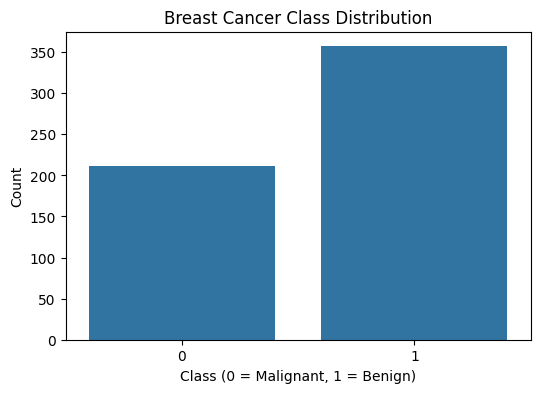

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(x=y)

plt.title("Breast Cancer Class Distribution")
plt.xlabel("Class (0 = Malignant, 1 = Benign)")
plt.ylabel("Count")

plt.show()

In [ ]:
# Check missing values

print("Missing values:", X.isnull().sum().sum())

# Check duplicate records

print("Duplicate records:", X.duplicated().sum())

# Separate input and target variables

print("\nInput Features Shape:", X.shape)
print("Target Shape:", y.shape)

Missing values: 0
Duplicate records: 0

Input Features Shape: (569, 30)
Target Shape: (569,)


In [ ]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Labels:", y_train.shape)
print("Testing Labels:", y_test.shape)

Training Data: (455, 30)
Testing Data: (114, 30)
Training Labels: (455,)
Testing Labels: (114,)


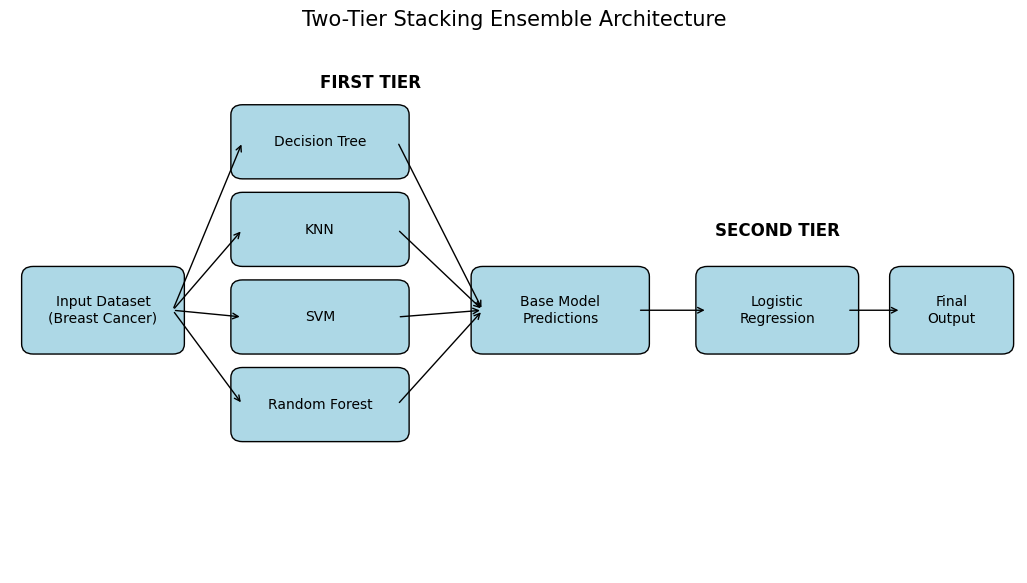

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(13, 7))

ax.set_xlim(0, 13)
ax.set_ylim(0, 8)
ax.axis("off")

def draw_box(x, y, width, height, text):
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.15",
        edgecolor="black",
        facecolor="lightblue"
    )
    ax.add_patch(box)
    ax.text(
        x + width/2, y + height/2,
        text, ha="center", va="center",
        fontsize=10
    )

# Input dataset
draw_box(0.3, 3.4, 1.8, 1.0, "Input Dataset\n(Breast Cancer)")

# First tier models
draw_box(3.0, 6.0, 2.0, 0.8, "Decision Tree")
draw_box(3.0, 4.7, 2.0, 0.8, "KNN")
draw_box(3.0, 3.4, 2.0, 0.8, "SVM")
draw_box(3.0, 2.1, 2.0, 0.8, "Random Forest")

# Prediction stage
draw_box(6.1, 3.4, 2.0, 1.0, "Base Model\nPredictions")

# Meta classifier
draw_box(9.0, 3.4, 1.8, 1.0, "Logistic\nRegression")

# Final output
draw_box(11.5, 3.4, 1.3, 1.0, "Final\nOutput")

# Arrows from input to models
for y in [6.4, 5.1, 3.8, 2.5]:
    ax.annotate(
        "", xy=(3.0, y), xytext=(2.1, 3.9),
        arrowprops=dict(arrowstyle="->")
    )

# Arrows from models to prediction stage
for y in [6.4, 5.1, 3.8, 2.5]:
    ax.annotate(
        "", xy=(6.1, 3.9), xytext=(5.0, y),
        arrowprops=dict(arrowstyle="->")
    )

# Remaining arrows
ax.annotate("", xy=(9.0, 3.9), xytext=(8.1, 3.9),
            arrowprops=dict(arrowstyle="->"))

ax.annotate("", xy=(11.5, 3.9), xytext=(10.8, 3.9),
            arrowprops=dict(arrowstyle="->"))

ax.text(4.0, 7.2, "FIRST TIER", fontsize=12, weight="bold")
ax.text(9.1, 5.0, "SECOND TIER", fontsize=12, weight="bold")

plt.title("Two-Tier Stacking Ensemble Architecture", fontsize=15)
plt.show()

In [ ]:
# Define four base classification models

base_models = [
    ('decision_tree', DecisionTreeClassifier(
        random_state=42
    )),

    ('knn', make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )),

    ('svm', make_pipeline(
        StandardScaler(),
        SVC(probability=True, random_state=42)
    )),

    ('random_forest', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
]

print("Four base learners defined successfully!")

Four base learners defined successfully!


In [ ]:
# Train individual base models

trained_models = {}

for name, model in base_models:

    model.fit(X_train, y_train)

    trained_models[name] = model

    print(name, "trained successfully!")

decision_tree trained successfully!
knn trained successfully!
svm trained successfully!
random_forest trained successfully!


In [ ]:
# Define the meta-classifier

meta_model = LogisticRegression(max_iter=1000)

# Create two-tier stacking classifier

stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=5,
    stack_method='predict_proba',
    passthrough=False
)

print("Two-tier stacking model created successfully!")

Two-tier stacking model created successfully!


In [ ]:
# Train the stacking model

stacking_model.fit(X_train, y_train)

print("Stacking Ensemble Model trained successfully!")

Stacking Ensemble Model trained successfully!


In [ ]:
# Generate predictions from individual models

predictions = {}

for name, model in trained_models.items():

    predictions[name] = model.predict(X_test)

# Generate stacking model predictions

predictions['Stacking Ensemble'] = stacking_model.predict(X_test)

print("Predictions generated successfully!")

print("\nSample Stacking Predictions:")
print(predictions['Stacking Ensemble'][:10])

Predictions generated successfully!

Sample Stacking Predictions:
[0 1 0 0 0 1 1 0 0 0]


In [ ]:
# Evaluate all models

results = []

for name, y_pred in predictions.items():

    if name == 'Stacking Ensemble':
        model = stacking_model
    else:
        model = trained_models[name]

    # Probability of malignant class (class 0)
    y_prob = model.predict_proba(X_test)[:, 0]

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, pos_label=0
    )

    recall = recall_score(
        y_test, y_pred, pos_label=0
    )

    f1 = f1_score(
        y_test, y_pred, pos_label=0
    )

    auc = roc_auc_score(
        (y_test == 0).astype(int), y_prob
    )

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'ROC-AUC': auc
    })

print("Performance evaluation completed!")

Performance evaluation completed!


In [ ]:
# Create comparison table

results_df = pd.DataFrame(results)

print("\nCOMPARATIVE PERFORMANCE TABLE\n")

print(
    results_df.to_string(
        index=False,
        formatters={
            'Accuracy': '{:.4f}'.format,
            'Precision': '{:.4f}'.format,
            'Recall': '{:.4f}'.format,
            'F1-Score': '{:.4f}'.format,
            'ROC-AUC': '{:.4f}'.format
        }
    )
)


COMPARATIVE PERFORMANCE TABLE

            Model Accuracy Precision Recall F1-Score ROC-AUC
    decision_tree   0.9123    0.8478 0.9286   0.8864  0.9157
              knn   0.9561    0.9512 0.9286   0.9398  0.9788
              svm   0.9825    0.9762 0.9762   0.9762  0.9950
    random_forest   0.9561    0.9512 0.9286   0.9398  0.9937
Stacking Ensemble   0.9649    0.9524 0.9524   0.9524  0.9940


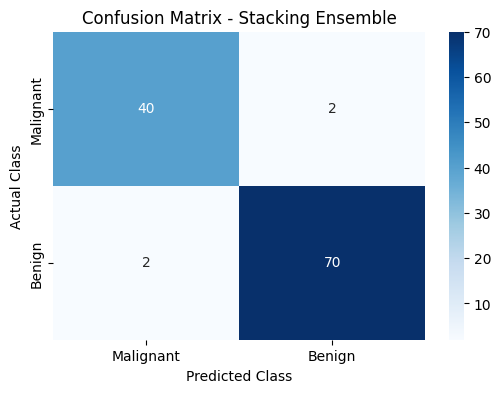

In [ ]:
# Confusion matrix for stacking model

cm = confusion_matrix(
    y_test,
    predictions['Stacking Ensemble'],
    labels=[0, 1]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Malignant', 'Benign'],
    yticklabels=['Malignant', 'Benign']
)

plt.title("Confusion Matrix - Stacking Ensemble")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

In [ ]:
print("Classification Report - Stacking Ensemble\n")

print(
    classification_report(
        y_test,
        predictions['Stacking Ensemble'],
        target_names=['Malignant', 'Benign']
    )
)

Classification Report - Stacking Ensemble

              precision    recall  f1-score   support

   Malignant       0.95      0.95      0.95        42
      Benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



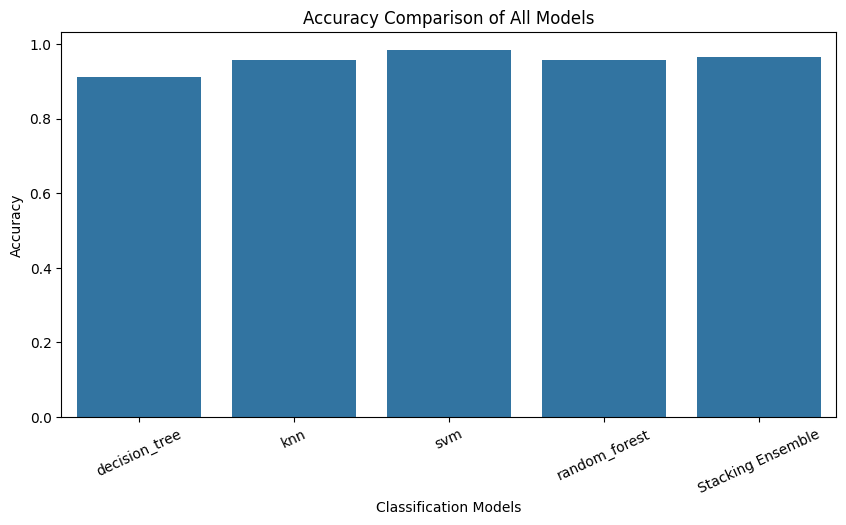

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

plt.title("Accuracy Comparison of All Models")
plt.xlabel("Classification Models")
plt.ylabel("Accuracy")

plt.xticks(rotation=25)

plt.show()

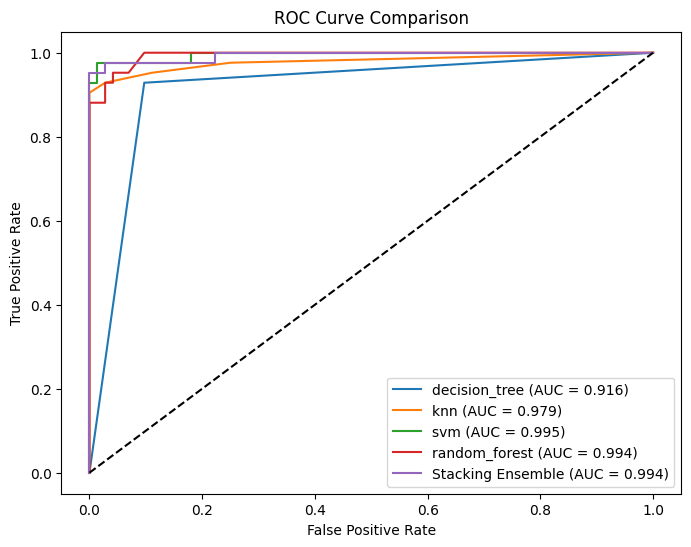

In [ ]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, y_pred in predictions.items():

    if name == 'Stacking Ensemble':
        model = stacking_model
    else:
        model = trained_models[name]

    y_prob = model.predict_proba(X_test)[:, 0]

    fpr, tpr, thresholds = roc_curve(
        (y_test == 0).astype(int),
        y_prob
    )

    auc = roc_auc_score(
        (y_test == 0).astype(int),
        y_prob
    )

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc:.3f})'
    )

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve Comparison")

plt.legend()
plt.show()

In [ ]:
# Find model with highest accuracy

best_model = results_df.loc[
    results_df['Accuracy'].idxmax()
]

print("Best Performing Model:")
print(best_model)

# Compare stacking with the best individual model

individual_results = results_df[
    results_df['Model'] != 'Stacking Ensemble'
]

best_individual = individual_results.loc[
    individual_results['Accuracy'].idxmax()
]

stacking_accuracy = results_df.loc[
    results_df['Model'] == 'Stacking Ensemble',
    'Accuracy'
].iloc[0]

print("\nBest Individual Model:")
print(best_individual['Model'])

print("\nStacking Accuracy:", stacking_accuracy)

print("Best Individual Accuracy:", best_individual['Accuracy'])

if stacking_accuracy > best_individual['Accuracy']:
    print("\nStacking improved the accuracy!")
elif stacking_accuracy == best_individual['Accuracy']:
    print("\nStacking achieved the same accuracy.")
else:
    print("\nStacking did not improve the accuracy.")

Best Performing Model:
Model             svm
Accuracy     0.982456
Precision     0.97619
Recall        0.97619
F1-Score      0.97619
ROC-AUC       0.99504
Name: 2, dtype: object

Best Individual Model:
svm

Stacking Accuracy: 0.9649122807017544
Best Individual Accuracy: 0.9824561403508771

Stacking did not improve the accuracy.
